#### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

#### Loading the Dataset

In [3]:
df = pd.read_csv("../data/raw/Hotel Reservations.csv")
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


#### Examining Dataset Dimensions

In [4]:
print(f"Number of Rows: {df.shape[0]:,}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 36,275
Number of Columns: 19


#### Examining Dataset Structure

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  str    
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  str    
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  str    
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date              

#### Key Observations
- **Dataset Size:** The dataset contains 36,275 hotel reservation records across 19 columns, providing reservation-level information for subsequent analysis.
- **Feature Composition:** The dataset consists of 14 numerical and 5 string columns, covering guest characteristics, reservation details, pricing, arrival dates, and booking status.
- **Data Completeness:** All 19 columns contain 36,275 non-null values, indicating no missing values in the original dataset.
- **Temporal Structure:** Arrival information is stored across `arrival_year`, `arrival_month`, and `arrival_date`, which will require validation and conversion into a unified date variable for time series analysis.

#### Identifying Feature Types

In [6]:
numerical_cols = df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print(f"Numerical Features ({len(numerical_cols)}):")
print(numerical_cols)

print(f"\nCategorical Features ({len(categorical_cols)}):")
print(categorical_cols)

Numerical Features (14):
['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests']

Categorical Features (5):
['Booking_ID', 'type_of_meal_plan', 'room_type_reserved', 'market_segment_type', 'booking_status']


#### Key Observations
- **Numerical Features:** The dataset contains 14 numerical columns representing guest counts, stay duration, booking lead time, arrival dates, pricing, and reservation history.
- **Categorical Features:** Five string columns describe booking identifiers, meal plans, room types, market segments, and booking status.
- **Feature Interpretation:** `Booking_ID` serves as a reservation identifier, while `arrival_year`, `arrival_month`, and `arrival_date` represent temporal components. Binary indicators such as `repeated_guest` and `required_car_parking_space` are numerically encoded categorical variables.

#### Examining Missing Values

In [7]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})
missing_values

,Missing_Count,Missing_Percentage
Booking_ID,0,0.0
no_of_adults,0,0.0
no_of_children,0,0.0
no_of_weekend_nights,0,0.0
no_of_week_nights,0,0.0
type_of_meal_plan,0,0.0
required_car_parking_space,0,0.0
room_type_reserved,0,0.0
lead_time,0,0.0
arrival_year,0,0.0


#### Key Observations
- **Complete Data Availability:** All 19 columns contain zero missing values, indicating that no missing-value imputation is required based on the initial inspection.
- **Data Quality Considerations:** Although the dataset has no null values, further validation is necessary to identify duplicate records, invalid dates, inconsistent categories, and potentially unrealistic numerical values.

#### Examining Duplicate Records

In [8]:
print(f"Fully Duplicated Records: {df.duplicated().sum():,}")
print(f"Duplicated Booking IDs: {df['Booking_ID'].duplicated().sum():,}")
print(f"Unique Booking IDs: {df['Booking_ID'].nunique():,}")

Fully Duplicated Records: 0
Duplicated Booking IDs: 0
Unique Booking IDs: 36,275


#### Key Observations
- **Duplicate Records:** No fully duplicated records were identified across the 36,275 reservations, indicating that each record is distinct.
- **Booking ID Integrity:** All 36,275 booking identifiers are unique, with no duplicated IDs, confirming a one-to-one relationship between booking identifiers and reservation records.

#### Examining Numerical Feature Statistics

In [9]:
df[numerical_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.84,0.52,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.11,0.40,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.81,0.87,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.20,1.41,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.03,0.17,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.23,85.93,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.82,0.38,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.42,3.07,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.60,8.74,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.03,0.16,0.0,0.0,0.00,0.0,1.0


#### Key Observations
- **Guest Composition:** Reservations typically involve two adults and no children, although child counts reach a maximum of 10, warranting further validation of unusually large bookings.
- **Stay Duration:** Reservations average approximately 3 nights, comprising 0.81 weekend nights and 2.20 weekday nights, with some substantially longer stays.
- **Booking Lead Time:** Reservations are made an average of 85.23 days before arrival, with a median of 57 days and a maximum of 443 days, indicating considerable variation in advance booking behavior.
- **Room Pricing:** The average room price is 103.42, with values ranging from 0 to 540. Zero-priced reservations and unusually high prices require further investigation.
- **Temporal Coverage:** Arrival years range from 2017 to 2018. The exact date range, continuity, and daily reservation coverage must be validated before establishing a forecasting strategy.

#### Examining Categorical Feature Distributions

In [10]:
for col in categorical_cols:
    if col == "Booking_ID":
        continue
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(df[col].value_counts().to_string())


type_of_meal_plan (4 unique values):
type_of_meal_plan
Meal Plan 1     27835
Not Selected     5130
Meal Plan 2      3305
Meal Plan 3         5

room_type_reserved (7 unique values):
room_type_reserved
Room_Type 1    28130
Room_Type 4     6057
Room_Type 6      966
Room_Type 2      692
Room_Type 5      265
Room_Type 7      158
Room_Type 3        7

market_segment_type (5 unique values):
market_segment_type
Online           23214
Offline          10528
Corporate         2017
Complementary      391
Aviation           125

booking_status (2 unique values):
booking_status
Not_Canceled    24390
Canceled        11885


#### Key Observations
- **Meal Plan Preferences:** Meal Plan 1 dominates with 27,835 reservations (76.73%), while Meal Plan 3 is exceptionally rare, appearing in only 5 reservations.
- **Room Type Distribution:** Room_Type 1 accounts for 28,130 reservations (77.55%), indicating a strong concentration in one room category.
- **Market Segmentation:** Online bookings represent 23,214 reservations (63.99%), followed by Offline bookings with 10,528 (29.02%), making these the primary reservation channels.
- **Booking Status:** Of the 36,275 reservations, 24,390 (67.24%) were not canceled, while 11,885 (32.76%) were canceled. Cancellation behavior is therefore an important consideration when defining the forecasting target.

#### Validating Arrival Dates

In [11]:
arrival_dates = pd.to_datetime(
    df[["arrival_year", "arrival_month", "arrival_date"]].rename(
        columns={
            "arrival_year": "year",
            "arrival_month": "month",
            "arrival_date": "day"
        }
    ),
    errors="coerce"
)

print(f"Valid Arrival Dates: {arrival_dates.notna().sum():,}")
print(f"Invalid Arrival Dates: {arrival_dates.isna().sum():,}")
print(f"Earliest Arrival Date: {arrival_dates.min()}")
print(f"Latest Arrival Date: {arrival_dates.max()}")
print(f"Unique Arrival Dates: {arrival_dates.nunique():,}")

Valid Arrival Dates: 36,238
Invalid Arrival Dates: 37
Earliest Arrival Date: 2017-07-01 00:00:00
Latest Arrival Date: 2018-12-31 00:00:00
Unique Arrival Dates: 549


#### Key Observations
- **Date Validity:** Of the 36,275 reservations, 36,238 (99.90%) contain valid arrival dates, while 37 (0.10%) contain invalid date combinations requiring investigation.
- **Temporal Coverage:** Valid arrival dates span July 1, 2017, through December 31, 2018, covering 549 unique arrival dates. Calendar continuity and daily reservation frequency must be examined before confirming forecasting suitability.

#### Investigating Invalid Arrival Dates

In [12]:
invalid_dates = df.loc[
    arrival_dates.isna(),
    ["arrival_year", "arrival_month", "arrival_date"]
]

print(f"Total Invalid Records: {len(invalid_dates):,}")
print("\nInvalid Date Combinations:")
print(
    invalid_dates.value_counts()
    .reset_index(name="Count")
    .to_string(index=False)
)

Total Invalid Records: 37

Invalid Date Combinations:
 arrival_year  arrival_month  arrival_date  Count
         2018              2            29     37


#### Key Observations
- **Systematic Date Inconsistency:** All 37 invalid reservations are assigned to February 29, 2018, which is not a valid calendar date because 2018 was not a leap year.
- **Data Preparation Decision:** The affected records represent approximately 0.10% of the dataset. Their arrival dates cannot be reliably corrected without additional evidence, so they will be flagged for exclusion from date-dependent forecasting analysis while preserving the original records.


#### Examining Daily Arrival Coverage

In [13]:
daily_arrivals = arrival_dates.value_counts().sort_index()

calendar_dates = pd.date_range(
    start=arrival_dates.min(),
    end=arrival_dates.max(),
    freq="D"
)

missing_dates = calendar_dates.difference(daily_arrivals.index)

print(f"Total Calendar Days: {len(calendar_dates):,}")
print(f"Days With Reservations: {len(daily_arrivals):,}")
print(f"Days Without Reservations: {len(missing_dates):,}")
print(f"Calendar Coverage: {len(daily_arrivals) / len(calendar_dates) * 100:.2f}%")
print(f"Minimum Daily Reservations: {daily_arrivals.min():,}")
print(f"Maximum Daily Reservations: {daily_arrivals.max():,}")
print(f"Average Daily Reservations: {daily_arrivals.mean():.2f}")

print("\nDates Without Reservations:")
print(missing_dates)

Total Calendar Days: 549
Days With Reservations: 549
Days Without Reservations: 0
Calendar Coverage: 100.00%
Minimum Daily Reservations: 1
Maximum Daily Reservations: 254
Average Daily Reservations: 66.01

Dates Without Reservations:
DatetimeIndex([], dtype='datetime64[us]', freq='D')


#### Key Observations
- **Complete Calendar Coverage:** All 549 calendar days between July 1, 2017, and December 31, 2018, contain at least one valid-dated reservation, resulting in 100% daily coverage without missing calendar dates.
- **Daily Reservation Variability:** Daily reservation counts range from 1 to 254, averaging 66.01 reservations per day, indicating substantial variation in scheduled arrival volumes.
- **Forecasting Feasibility:** The continuous daily series provides a suitable initial structure for time series analysis, although cancellation effects, temporal patterns, and data completeness require further investigation before finalizing the forecasting target.

#### Examining Yearly and Monthly Arrival Coverage

In [14]:
monthly_coverage = (
    pd.DataFrame({"Arrival_Date": arrival_dates.dropna()})
    .assign(
        Year=lambda x: x["Arrival_Date"].dt.year,
        Month=lambda x: x["Arrival_Date"].dt.month
    )
    .groupby(["Year", "Month"])
    .agg(
        Reservation_Count=("Arrival_Date", "size"),
        Days_Represented=("Arrival_Date", "nunique")
    )
    .reset_index()
)

monthly_coverage["Calendar_Days"] = pd.to_datetime(
    monthly_coverage[["Year", "Month"]].assign(day=1)
    .rename(columns={"Year": "year", "Month": "month"})
).dt.days_in_month

monthly_coverage["Average_Daily_Reservations"] = (
    monthly_coverage["Reservation_Count"] /
    monthly_coverage["Days_Represented"]
).round(2)

monthly_coverage

,Year,Month,Reservation_Count,Days_Represented,Calendar_Days,Average_Daily_Reservations
0,2017,7,363,31,31,11.71
1,2017,8,1014,31,31,32.71
2,2017,9,1649,30,30,54.97
3,2017,10,1913,31,31,61.71
4,2017,11,647,30,30,21.57
5,2017,12,928,31,31,29.94
6,2018,1,1014,31,31,32.71
7,2018,2,1667,28,28,59.54
8,2018,3,2358,31,31,76.06
9,2018,4,2736,30,30,91.20


#### Key Observations
- **Monthly Calendar Coverage:** All 18 months from July 2017 through December 2018 have complete daily representation, confirming continuous monthly coverage across the observed period.
- **Reservation Volume Growth:** Average daily reservations increased from 11.71 in July 2017 to 109.81 in October 2018, with October 2018 recording the highest monthly volume of 3,404 reservations.
- **Temporal Variation:** Monthly reservation volumes fluctuate considerably, with 2018 generally recording higher activity than 2017. However, the limited historical period prevents reliable conclusions about recurring annual seasonality.

#### Examining Daily Arrival Distribution

In [15]:
daily_arrival_stats = daily_arrivals.describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
)

print("Daily Arrival Distribution:")
print(daily_arrival_stats.round(2).to_string())

print(f"\nDays With Fewer Than 10 Reservations: {(daily_arrivals < 10).sum():,}")
print(f"Days With More Than 150 Reservations: {(daily_arrivals > 150).sum():,}")

Daily Arrival Distribution:
count    549.00
mean      66.01
std       43.56
min        1.00
5%         7.00
25%       32.00
50%       61.00
75%       92.00
95%      144.60
max      254.00

Days With Fewer Than 10 Reservations: 36
Days With More Than 150 Reservations: 24


#### Key Observations
- **Daily Reservation Volume:** The dataset records an average of 66.01 reservations per day, with a median of 61 and a standard deviation of 43.56, indicating substantial variation in daily volumes.
- **Reservation Distribution:** Half of the observed days contain between 32 and 92 reservations, while daily counts range from 1 to 254, demonstrating considerable differences in reservation activity.
- **Extreme Daily Volumes:** There are 36 days with fewer than 10 reservations and 24 days with more than 150, highlighting periods of unusually low and high scheduled arrival volumes that warrant further temporal investigation.

#### Examining Cancellation-Adjusted Daily Arrivals

In [16]:
daily_booking_status = (
    pd.DataFrame({
        "Arrival_Date": arrival_dates,
        "Booking_Status": df["booking_status"]
    })
    .dropna(subset=["Arrival_Date"])
    .groupby(["Arrival_Date", "Booking_Status"])
    .size()
    .unstack(fill_value=0)
    .reindex(calendar_dates, fill_value=0)
)

daily_booking_status["Total_Reservations"] = (
    daily_booking_status["Canceled"] +
    daily_booking_status["Not_Canceled"]
)

daily_booking_status["Cancellation_Rate"] = (
    daily_booking_status["Canceled"] /
    daily_booking_status["Total_Reservations"] * 100
).round(2)

daily_booking_status.head(10)

Booking_Status,Canceled,Not_Canceled,Total_Reservations,Cancellation_Rate
2017-07-01,52,16,68,76.47
2017-07-02,5,0,5,100.00
2017-07-03,2,1,3,66.67
2017-07-04,4,0,4,100.00
2017-07-05,3,0,3,100.00
2017-07-06,10,0,10,100.00
2017-07-07,10,4,14,71.43
2017-07-08,5,2,7,71.43
2017-07-09,3,1,4,75.00
2017-07-10,4,1,5,80.00


#### Key Observations
- **Cancellation-Adjusted Arrivals:** Daily reservation counts differ substantially after accounting for cancellation status. On July 1, 2017, 52 of 68 reservations were canceled, leaving 16 non-canceled reservations.
- **High Initial Cancellation Rates:** Several dates in early July 2017 exhibit cancellation rates between 66.67% and 100%, including four days with no non-canceled reservations.
- **Forecasting Implications:** Cancellation-adjusted counts provide a potential proxy for realized arrivals, but their suitability as a forecasting target requires further investigation because actual check-ins and cancellation timestamps are unavailable.

#### Examining Overall Cancellation Patterns

In [17]:
cancellation_summary = pd.DataFrame({
    "Metric": [
        "Total Reservations",
        "Canceled Reservations",
        "Non-Canceled Reservations",
        "Overall Cancellation Rate (%)",
        "Average Daily Cancellations",
        "Average Daily Non-Canceled Reservations",
        "Days With Zero Non-Canceled Reservations"
    ],
    "Value": [
        daily_booking_status["Total_Reservations"].sum(),
        daily_booking_status["Canceled"].sum(),
        daily_booking_status["Not_Canceled"].sum(),
        daily_booking_status["Canceled"].sum() /
        daily_booking_status["Total_Reservations"].sum() * 100,
        daily_booking_status["Canceled"].mean(),
        daily_booking_status["Not_Canceled"].mean(),
        (daily_booking_status["Not_Canceled"] == 0).sum()
    ]
})

cancellation_summary["Value"] = cancellation_summary["Value"].round(2)

cancellation_summary

,Metric,Value
0,Total Reservations,36238.00
1,Canceled Reservations,11878.00
2,Non-Canceled Reservations,24360.00
3,Overall Cancellation Rate (%),32.78
4,Average Daily Cancellations,21.64
5,Average Daily Non-Canceled Reservations,44.37
6,Days With Zero Non-Canceled Reservations,12.00


#### Key Observations
- **Overall Cancellation Rate:** Of the 36,238 reservations with valid arrival dates, 11,878 (32.78%) were canceled, while 24,360 (67.22%) remained non-canceled.
- **Cancellation-Adjusted Volume:** Daily averages decrease from 66.01 total reservations to 44.37 non-canceled reservations, demonstrating the substantial effect of cancellations on scheduled arrival volumes.
- **Zero-Arrival Days:** Twelve dates contain no non-canceled reservations, highlighting the importance of preserving zero values when constructing a cancellation-adjusted daily time series.

#### Examining Monthly Cancellation Patterns

In [18]:
monthly_cancellation_summary = (
    daily_booking_status[
        ["Canceled", "Not_Canceled", "Total_Reservations"]
    ]
    .resample("MS")
    .sum()
)

monthly_cancellation_summary["Cancellation_Rate"] = (
    monthly_cancellation_summary["Canceled"] /
    monthly_cancellation_summary["Total_Reservations"] * 100
).round(2)

monthly_cancellation_summary["Average_Daily_Non_Canceled"] = (
    monthly_cancellation_summary["Not_Canceled"] /
    monthly_cancellation_summary.index.days_in_month
).round(2)

monthly_cancellation_summary

Booking_Status,Canceled,Not_Canceled,Total_Reservations,Cancellation_Rate,Average_Daily_Non_Canceled
2017-07-01,243,120,363,66.94,3.87
2017-08-01,185,829,1014,18.24,26.74
2017-09-01,182,1467,1649,11.04,48.90
2017-10-01,302,1611,1913,15.79,51.97
2017-11-01,27,620,647,4.17,20.67
2017-12-01,22,906,928,2.37,29.23
2018-01-01,24,990,1014,2.37,31.94
2018-02-01,423,1244,1667,25.37,44.43
2018-03-01,700,1658,2358,29.69,53.48
2018-04-01,995,1741,2736,36.37,58.03


#### Key Observations
- **Cancellation Rate Variability:** Monthly cancellation rates range from 2.37% in December 2017 and January 2018 to 66.94% in July 2017, indicating substantial changes in cancellation behavior across the observation period.
- **Changing Cancellation Patterns:** Cancellation rates generally increase throughout much of 2018, reaching 46.55% in August before declining to 18.16% in December. These differences warrant further investigation rather than being attributed to seasonality without additional evidence.
- **Non-Canceled Reservation Volumes:** Average daily non-canceled reservations range from 3.87 in July 2017 to 63.73 in June 2018, demonstrating considerable variation in cancellation-adjusted arrival volumes.

#### Examining Yearly Reservation and Cancellation Patterns

In [19]:
yearly_summary = (
    daily_booking_status[
        ["Canceled", "Not_Canceled", "Total_Reservations"]
    ]
    .resample("YS")
    .sum()
)

yearly_summary["Days_Observed"] = (
    daily_booking_status["Total_Reservations"]
    .resample("YS")
    .size()
)

yearly_summary["Average_Daily_Reservations"] = (
    yearly_summary["Total_Reservations"] /
    yearly_summary["Days_Observed"]
).round(2)

yearly_summary["Average_Daily_Non_Canceled"] = (
    yearly_summary["Not_Canceled"] /
    yearly_summary["Days_Observed"]
).round(2)

yearly_summary["Cancellation_Rate"] = (
    yearly_summary["Canceled"] /
    yearly_summary["Total_Reservations"] * 100
).round(2)

yearly_summary

Booking_Status,Canceled,Not_Canceled,Total_Reservations,Days_Observed,Average_Daily_Reservations,Average_Daily_Non_Canceled,Cancellation_Rate
2017-01-01,961,5553,6514,184,35.40,30.18,14.75
2018-01-01,10917,18807,29724,365,81.44,51.53,36.73


#### Key Observations
- **Reservation Volume:** Average daily reservations increased from 35.40 across 184 observed days in 2017 to 81.44 across 365 days in 2018, indicating substantially higher recorded reservation activity.
- **Cancellation Behavior:** The cancellation rate increased from 14.75% in 2017 to 36.73% in 2018, while average daily non-canceled reservations increased from 30.18 to 51.53.
- **Comparison Limitations:** Since 2017 covers only six months, the yearly figures are not directly comparable as full-year performance measures. Differences may reflect seasonality, changes in booking behavior, or dataset coverage.

#### Examining Comparable Monthly Reservation Patterns

In [20]:
comparable_months = monthly_cancellation_summary.loc[
    monthly_cancellation_summary.index.month >= 7
].copy()

comparable_months["Year"] = comparable_months.index.year
comparable_months["Month"] = comparable_months.index.month

comparison = comparable_months.pivot(
    index="Month",
    columns="Year",
    values=[
        "Total_Reservations",
        "Not_Canceled",
        "Cancellation_Rate"
    ]
)

comparison.columns = [
    f"{metric}_{year}"
    for metric, year in comparison.columns
]

comparison["Reservation_Change_Pct"] = (
    (comparison["Total_Reservations_2018"] /
     comparison["Total_Reservations_2017"] - 1) * 100
).round(2)

comparison["Non_Canceled_Change_Pct"] = (
    (comparison["Not_Canceled_2018"] /
     comparison["Not_Canceled_2017"] - 1) * 100
).round(2)

comparison.round(2)

,Total_Reservations_2017,Total_Reservations_2018,Not_Canceled_2017,Not_Canceled_2018,Cancellation_Rate_2017,Cancellation_Rate_2018,Reservation_Change_Pct,Non_Canceled_Change_Pct
Month,,,,,,,,
7,363.0,2557.0,120.0,1486.0,66.94,41.89,604.41,1138.33
8,1014.0,2799.0,829.0,1496.0,18.24,46.55,176.04,80.46
9,1649.0,2962.0,1467.0,1606.0,11.04,45.78,79.62,9.48
10,1913.0,3404.0,1611.0,1826.0,15.79,46.36,77.94,13.35
11,647.0,2333.0,620.0,1485.0,4.17,36.35,260.59,139.52
12,928.0,2093.0,906.0,1713.0,2.37,18.16,125.54,89.07


#### Key Observations
- **Reservation Volume Differences:** Total reservations increased across all six comparable months, with changes ranging from 77.94% in October to 604.41% in July. These differences indicate substantially higher recorded volumes in 2018 but do not independently establish underlying demand growth.
- **Cancellation Rate Changes:** Cancellation rates were higher in five of the six comparable months in 2018, with September increasing from 11.04% to 45.78%. July was the exception, declining from 66.94% to 41.89%.
- **Non-Canceled Reservation Patterns:** Non-canceled reservations increased across all comparable months, although September and October recorded relatively modest increases of 9.48% and 13.35%, respectively, highlighting the influence of changing cancellation patterns.

#### Examining Arrival Patterns by Day of Week

In [23]:
weekday_summary = daily_booking_status[
    ["Canceled", "Not_Canceled", "Total_Reservations"]
].copy()

weekday_summary["Day_of_Week"] = weekday_summary.index.day_name()

weekday_summary = (
    weekday_summary.groupby("Day_of_Week")
    .agg(
        Days_Observed=("Total_Reservations", "size"),
        Average_Daily_Reservations=("Total_Reservations", "mean"),
        Average_Daily_Non_Canceled=("Not_Canceled", "mean"),
        Average_Daily_Cancellations=("Canceled", "mean")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
)

weekday_summary.round(2)

,Days_Observed,Average_Daily_Reservations,Average_Daily_Non_Canceled,Average_Daily_Cancellations
Day_of_Week,,,,
Monday,79,68.10,47.15,20.95
Tuesday,78,62.81,42.47,20.33
Wednesday,78,65.64,44.12,21.53
Thursday,78,58.26,39.92,18.33
Friday,78,60.78,41.46,19.32
Saturday,79,68.59,46.70,21.90
Sunday,79,77.66,48.66,29.00


#### Key Observations
- **Weekly Reservation Patterns:** Sunday records the highest average daily reservation volume at 77.66, while Thursday records the lowest at 58.26, indicating differences in scheduled arrivals across weekdays.
- **Non-Canceled Reservations:** Sunday also has the highest average daily non-canceled reservations at 48.66, followed by Monday at 47.15, while Thursday records the lowest at 39.92.
- **Cancellation Patterns:** Sunday records the highest average daily cancellations at 29.00, suggesting that weekday-related cancellation behavior may influence cancellation-adjusted arrival volumes.

#### Examining Weekly Pattern Stability

In [24]:
weekly_stability = daily_booking_status[
    ["Total_Reservations", "Not_Canceled"]
].copy()

weekly_stability["Year"] = weekly_stability.index.year
weekly_stability["Day_of_Week"] = weekly_stability.index.day_name()

weekly_stability_summary = (
    weekly_stability.groupby(["Day_of_Week", "Year"])
    .agg(
        Days_Observed=("Total_Reservations", "size"),
        Average_Daily_Reservations=("Total_Reservations", "mean"),
        Average_Daily_Non_Canceled=("Not_Canceled", "mean")
    )
    .round(2)
    .unstack("Year")
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
)

weekly_stability_summary

Days_Observed      Average_Daily_Reservations          \
Year                 2017 2018                       2017    2018   
Day_of_Week                                                         
Monday                 26   53                      63.31   70.45   
Tuesday                26   52                      32.35   78.04   
Wednesday              26   52                      21.62   87.65   
Thursday               26   52                      32.23   71.27   
Friday                 26   52                      31.27   75.54   
Saturday               27   52                      35.30   85.88   
Sunday                 27   52                      31.89  101.42   

            Average_Daily_Non_Canceled         
Year                              2017   2018  
Day_of_Week                                    
Monday                           51.77  44.89  
Tuesday                          24.96  51.23  
Wednesday                        19.73  56.31  
Thursday                         27.69  46.04  
Friday                           28.62  47.88  
Saturday                         30.33  55.19  
Sunday                           28.22  59.27

#### Key Observations
- **Changing Weekly Patterns:** Monday recorded the highest average daily reservation volume in 2017 at 63.31, while Sunday led in 2018 at 101.42, indicating that the weekday distribution changed across the observed periods.
- **Non-Canceled Reservation Patterns:** Monday recorded the highest average daily non-canceled volume in 2017 at 51.77, whereas Sunday led in 2018 at 59.27, suggesting differences in cancellation-adjusted arrival patterns.
- **Forecasting Implications:** The variation in weekday patterns indicates that weekly seasonality should not be assumed stable. Its predictive value must be assessed using chronological validation, particularly because 2017 contains only six months of observations.

#### Examining Reservation Lead Time

In [25]:
lead_time_summary = df["lead_time"].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
)

print("Reservation Lead Time Distribution:")
print(lead_time_summary.round(2).to_string())

print(f"\nSame-Day Reservations: {(df['lead_time'] == 0).sum():,}")
print(f"Reservations Made Within 7 Days: {(df['lead_time'] <= 7).sum():,}")
print(f"Reservations Made More Than 90 Days Ahead: {(df['lead_time'] > 90).sum():,}")
print(f"Reservations Made More Than 365 Days Ahead: {(df['lead_time'] > 365).sum():,}")

Reservation Lead Time Distribution:
count    36275.00
mean        85.23
std         85.93
min          0.00
5%           1.00
25%         17.00
50%         57.00
75%        126.00
95%        273.00
max        443.00

Same-Day Reservations: 1,297
Reservations Made Within 7 Days: 5,801
Reservations Made More Than 90 Days Ahead: 13,049
Reservations Made More Than 365 Days Ahead: 243


#### Key Observations
- **Booking Lead Time:** Reservations have an average lead time of 85.23 days and a median of 57 days, with values ranging from 0 to 443 days, indicating substantial variation in advance booking behavior.
- **Short-Term Reservations:** A total of 5,801 reservations (15.99%) were made within seven days of arrival, including 1,297 same-day reservations (3.58%).
- **Long-Term Reservations:** Approximately 35.97% of reservations were made more than 90 days before arrival, while 243 reservations had lead times exceeding one year.

#### Examining Reconstructed Booking Dates

In [26]:
booking_dates = arrival_dates - pd.to_timedelta(df["lead_time"], unit="D")

print(f"Valid Reconstructed Booking Dates: {booking_dates.notna().sum():,}")
print(f"Invalid Reconstructed Booking Dates: {booking_dates.isna().sum():,}")
print(f"Earliest Reconstructed Booking Date: {booking_dates.min()}")
print(f"Latest Reconstructed Booking Date: {booking_dates.max()}")
print(f"Unique Reconstructed Booking Dates: {booking_dates.nunique():,}")

print("\nReconstructed Booking Counts by Year:")
print(booking_dates.dt.year.value_counts().sort_index().to_string())

Valid Reconstructed Booking Dates: 36,238
Invalid Reconstructed Booking Dates: 37
Earliest Reconstructed Booking Date: 2016-10-17 00:00:00
Latest Reconstructed Booking Date: 2018-12-30 00:00:00
Unique Reconstructed Booking Dates: 635

Reconstructed Booking Counts by Year:
2016.0      132
2017.0    10648
2018.0    25458


#### Key Observations
- **Booking Date Reconstruction:** Booking dates were successfully reconstructed for 36,238 reservations (99.90%), while 37 records remain invalid because of their incorrect arrival dates.
- **Reconstructed Temporal Coverage:** Booking dates range from October 17, 2016, to December 30, 2018, covering 635 unique dates, with most reconstructed bookings occurring in 2018.
- **Forecasting Limitations:** Reconstructed booking dates do not guarantee complete historical booking activity because the dataset is organized around arrival dates. Reservations arriving outside the observed period may be absent, potentially introducing boundary-related selection bias.

#### Examining Reconstructed Booking Date Coverage

In [27]:
daily_bookings = booking_dates.value_counts().sort_index()

booking_calendar = pd.date_range(
    start=booking_dates.min(),
    end=booking_dates.max(),
    freq="D"
)

missing_booking_dates = booking_calendar.difference(daily_bookings.index)

print(f"Total Calendar Days: {len(booking_calendar):,}")
print(f"Days With Recorded Bookings: {len(daily_bookings):,}")
print(f"Days Without Recorded Bookings: {len(missing_booking_dates):,}")
print(f"Calendar Coverage: {len(daily_bookings) / len(booking_calendar) * 100:.2f}%")
print(f"Minimum Daily Bookings: {daily_bookings.min():,}")
print(f"Maximum Daily Bookings: {daily_bookings.max():,}")
print(f"Average Bookings per Active Day: {daily_bookings.mean():.2f}")

print("\nMonthly Reconstructed Booking Counts:")
print(
    daily_bookings.resample("MS")
    .sum()
    .to_string()
)

Total Calendar Days: 805
Days With Recorded Bookings: 635
Days Without Recorded Bookings: 170
Calendar Coverage: 78.88%
Minimum Daily Bookings: 1
Maximum Daily Bookings: 644
Average Bookings per Active Day: 57.07

Monthly Reconstructed Booking Counts:
2016-10-01     132
2016-11-01       0
2016-12-01       0
2017-01-01     149
2017-02-01      66
2017-03-01     184
2017-04-01     506
2017-05-01     123
2017-06-01     167
2017-07-01    1114
2017-08-01    1708
2017-09-01    1455
2017-10-01    1783
2017-11-01    1392
2017-12-01    2001
2018-01-01    4346
2018-02-01    3832
2018-03-01    2752
2018-04-01    2665
2018-05-01    2179
2018-06-01    1508
2018-07-01    1712
2018-08-01    1738
2018-09-01    1990
2018-10-01    1348
2018-11-01     923
2018-12-01     465
Freq: MS


#### Key Observations
- **Reconstructed Booking Coverage:** The inferred booking-date series spans 805 calendar days, with recorded bookings on 635 days (78.88%) and no recorded bookings on 170 days.
- **Booking Volume Variability:** Recorded booking counts range from 1 to 644 per active day, averaging 57.07 bookings across days with recorded activity.
- **Temporal Completeness Concerns:** The absence of recorded bookings throughout November and December 2016, combined with the arrival-date-based dataset selection, raises concerns about historical completeness and boundary-related bias. Missing dates cannot reliably be interpreted as zero actual bookings.

#### Examining Booking Date Boundary Effects

In [28]:
booking_boundary_summary = pd.DataFrame({
    "Booking_Date": booking_dates,
    "Arrival_Date": arrival_dates
}).dropna()

booking_boundary_summary["Days_Until_Arrival_Boundary"] = (
    arrival_dates.max() - booking_boundary_summary["Booking_Date"]
).dt.days

print(f"Latest Available Arrival Date: {arrival_dates.max().date()}")
print(f"Latest Reconstructed Booking Date: {booking_dates.max().date()}")

print("\nBookings Within Selected Periods Before Arrival Boundary:")

for days in [7, 30, 60, 90]:
    count = (
        booking_boundary_summary["Days_Until_Arrival_Boundary"] <= days
    ).sum()
    print(f"Within {days} Days: {count:,}")

print("\nLead Time Distribution:")
print(df["lead_time"].quantile([0.25, 0.50, 0.75, 0.95]))

Latest Available Arrival Date: 2018-12-31
Latest Reconstructed Booking Date: 2018-12-30

Bookings Within Selected Periods Before Arrival Boundary:
Within 7 Days: 39
Within 30 Days: 465
Within 60 Days: 1,388
Within 90 Days: 2,714

Lead Time Distribution:
0.25     17.0
0.50     57.0
0.75    126.0
0.95    273.0
Name: lead_time, dtype: float64


#### Key Observations
- **Booking Activity Near the Boundary:** Only 39 reconstructed bookings occur within seven days of the final arrival date, increasing to 465 within 30 days and 2,714 within 90 days.
- **Advance Booking Behavior:** The median lead time is 57 days, while 25% of reservations have lead times exceeding 126 days, indicating that a substantial portion of bookings are made well in advance.
- **Forecasting Implications:** Reservations created near December 31, 2018, for arrivals beyond that date are excluded from the dataset. Consequently, reconstructed booking counts near the boundary are incomplete and should not be interpreted as actual daily booking demand.

#### Examining Monthly Scheduled Arrival Volumes

In [29]:
monthly_arrival_summary = (
    daily_booking_status[
        ["Total_Reservations", "Canceled", "Not_Canceled"]
    ]
    .resample("MS")
    .agg(["sum", "mean"])
)

monthly_arrival_summary.columns = [
    "Total_Reservations",
    "Average_Daily_Reservations",
    "Total_Cancellations",
    "Average_Daily_Cancellations",
    "Total_Non_Canceled",
    "Average_Daily_Non_Canceled"
]

monthly_arrival_summary.round(2)

,Total_Reservations,Average_Daily_Reservations,Total_Cancellations,Average_Daily_Cancellations,Total_Non_Canceled,Average_Daily_Non_Canceled
2017-07-01,363,11.71,243,7.84,120,3.87
2017-08-01,1014,32.71,185,5.97,829,26.74
2017-09-01,1649,54.97,182,6.07,1467,48.90
2017-10-01,1913,61.71,302,9.74,1611,51.97
2017-11-01,647,21.57,27,0.90,620,20.67
2017-12-01,928,29.94,22,0.71,906,29.23
2018-01-01,1014,32.71,24,0.77,990,31.94
2018-02-01,1667,59.54,423,15.11,1244,44.43
2018-03-01,2358,76.06,700,22.58,1658,53.48
2018-04-01,2736,91.20,995,33.17,1741,58.03


#### Key Observations
- **Scheduled Reservation Volumes:** Monthly reservations increased from 363 in July 2017 to a peak of 3,404 in October 2018, with average daily reservations reaching 109.81 in October 2018.
- **Non-Canceled Reservation Patterns:** Non-canceled reservations peaked at 1,912 in June 2018, averaging 63.73 per day. Their monthly pattern differs from total reservations, reflecting the influence of cancellations.
- **Cancellation Variability:** Monthly cancellations reached 1,578 in October 2018, compared with just 24 in January 2018, indicating substantial changes in cancellation activity over the observed period.
- **Forecasting Implications:** The considerable variation in daily reservation volumes suggests that forecasting models must account for changing demand levels rather than relying exclusively on fixed seasonal patterns.

#### Examining Daily Reservation Trends

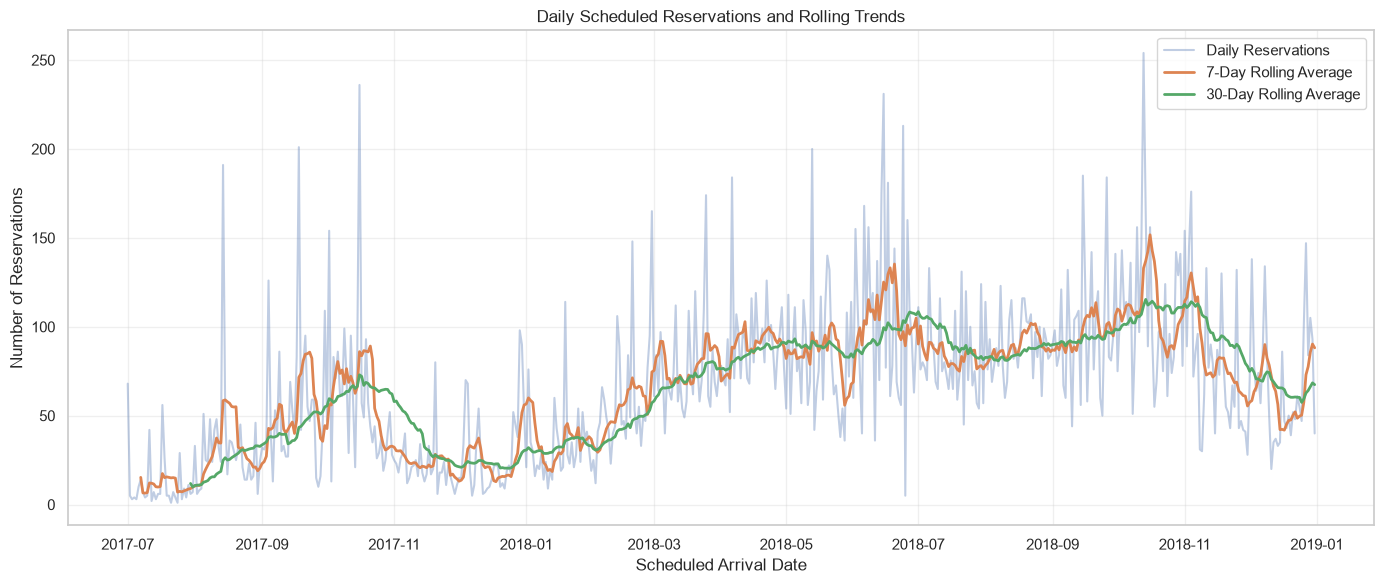

Daily Reservation Trend Summary:
       Daily_Reservations  Rolling_Average_7D  Rolling_Average_30D
count              549.00              543.00               520.00
mean                66.01               66.15                67.44
std                 43.56               31.99                28.76
min                  1.00                6.43                 9.83
25%                 32.00               36.79                37.87
50%                 61.00               72.86                72.87
75%                 92.00               89.43                90.32
max                254.00              151.71               115.40

Rolling Average Extremes:

Rolling_Average_7D:
Minimum: 6.43
Minimum Date: 2017-07-09
Maximum: 151.71
Maximum Date: 2018-10-16

Rolling_Average_30D:
Minimum: 9.83
Minimum Date: 2017-07-31
Maximum: 115.40
Maximum Date: 2018-10-14

Daily Reservation Volatility:
Standard Deviation: 43.56
Coefficient of Variation: 66.00%


In [32]:
import matplotlib.pyplot as plt

daily_reservation_trend = daily_booking_status["Total_Reservations"].copy()

rolling_average_7d = daily_reservation_trend.rolling(
    window=7, min_periods=7
).mean()

rolling_average_30d = daily_reservation_trend.rolling(
    window=30, min_periods=30
).mean()

trend_summary = pd.DataFrame({
    "Daily_Reservations": daily_reservation_trend,
    "Rolling_Average_7D": rolling_average_7d,
    "Rolling_Average_30D": rolling_average_30d
})

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    trend_summary.index,
    trend_summary["Daily_Reservations"],
    label="Daily Reservations",
    alpha=0.35
)

ax.plot(
    trend_summary.index,
    trend_summary["Rolling_Average_7D"],
    label="7-Day Rolling Average",
    linewidth=2
)

ax.plot(
    trend_summary.index,
    trend_summary["Rolling_Average_30D"],
    label="30-Day Rolling Average",
    linewidth=2
)

ax.set_title("Daily Scheduled Reservations and Rolling Trends")
ax.set_xlabel("Scheduled Arrival Date")
ax.set_ylabel("Number of Reservations")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Daily Reservation Trend Summary:")
print(trend_summary.describe().round(2).to_string())

print("\nRolling Average Extremes:")

for column in ["Rolling_Average_7D", "Rolling_Average_30D"]:
    print(f"\n{column}:")
    print(f"Minimum: {trend_summary[column].min():.2f}")
    print(f"Minimum Date: {trend_summary[column].idxmin().date()}")
    print(f"Maximum: {trend_summary[column].max():.2f}")
    print(f"Maximum Date: {trend_summary[column].idxmax().date()}")

print("\nDaily Reservation Volatility:")
print(f"Standard Deviation: {daily_reservation_trend.std():.2f}")
print(f"Coefficient of Variation: {daily_reservation_trend.std() / daily_reservation_trend.mean() * 100:.2f}%")

#### Key Observations
- **Daily Reservation Variability:** Daily reservations average 66.01, with a standard deviation of 43.56 and a coefficient of variation of 66.00%, indicating substantial fluctuations in scheduled arrival volumes.
- **Short-Term Trends:** The 7-day rolling average ranges from 6.43 on July 9, 2017, to 151.71 on October 16, 2018, highlighting considerable changes in short-term reservation activity.
- **Longer-Term Trends:** The 30-day rolling average increases from a minimum of 9.83 on July 31, 2017, to a maximum of 115.40 on October 14, 2018, demonstrating substantial variation in the underlying reservation level.
- **Forecasting Implications:** The changing trend and high daily variability suggest that forecasting models should capture both recent reservation behavior and broader temporal changes.

#### Examining Temporal Autocorrelation

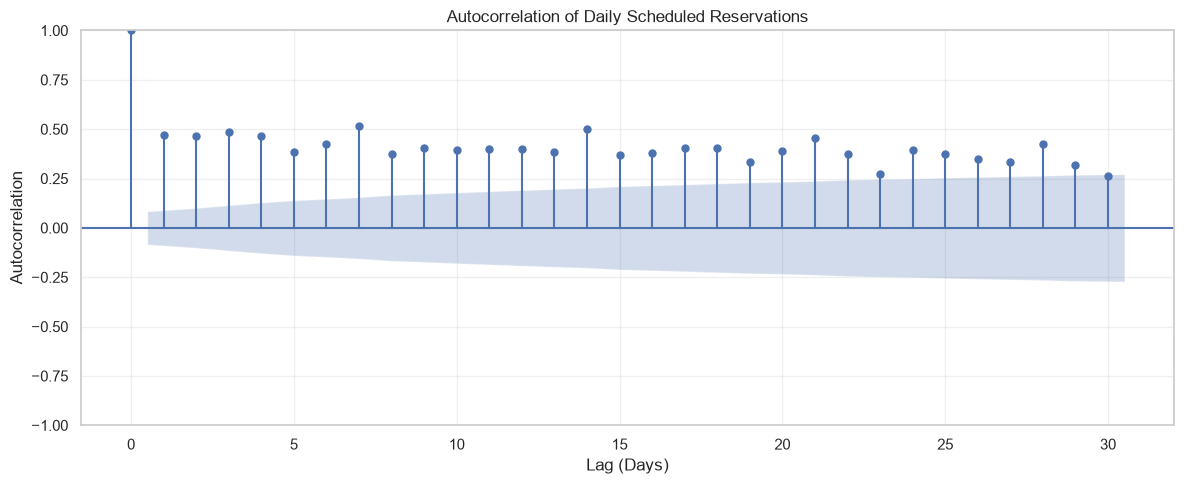

Selected Lag Autocorrelations:
 Lag_Days  Autocorrelation
        1           0.4714
        2           0.4673
        3           0.4879
        7           0.5222
       14           0.5137
       21           0.4745
       28           0.4502
       30           0.2834


In [33]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

daily_reservations = daily_booking_status["Total_Reservations"].copy()

selected_lags = [1, 2, 3, 7, 14, 21, 28, 30]

autocorrelation_summary = pd.DataFrame({
    "Lag_Days": selected_lags,
    "Autocorrelation": [
        daily_reservations.autocorr(lag=lag)
        for lag in selected_lags
    ]
})

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    daily_reservations,
    lags=30,
    alpha=0.05,
    ax=ax
)

ax.set_title("Autocorrelation of Daily Scheduled Reservations")
ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Autocorrelation")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Selected Lag Autocorrelations:")
print(
    autocorrelation_summary.round(4).to_string(index=False)
)

#### Key Observations
- **Short-Term Autocorrelation:** Daily reservations exhibit moderate positive autocorrelation at lags 1–3 (0.4673–0.4879), indicating that recent reservation volumes are associated with subsequent daily volumes.
- **Weekly Relationships:** Autocorrelation is strongest among the selected lags at 7 days (0.5222), followed by 14 days (0.5137), suggesting a potential weekly recurring pattern.
- **Forecasting Implications:** Positive autocorrelation persists through 28 days (0.4502), supporting further investigation of historical lag features. However, underlying trends may contribute to these correlations, so weekly seasonality requires additional validation.

#### Examining Time Series Stationarity

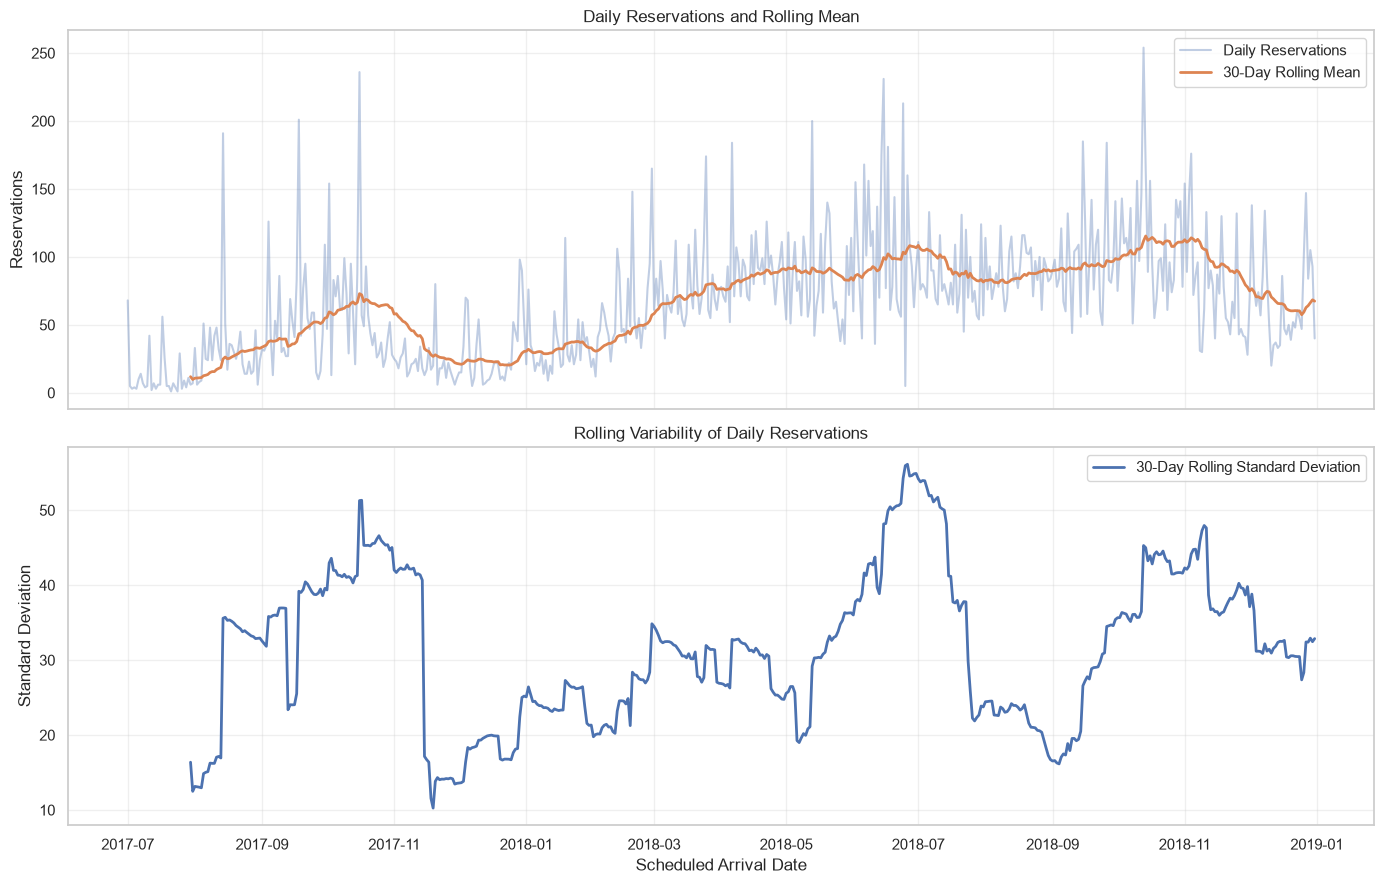

Augmented Dickey-Fuller Test:
ADF Statistic: -2.3093
P-Value: 0.168979
Lags Used: 13
Observations Used: 535

Critical Values:
1%: -3.4426
5%: -2.8670
10%: -2.5697

Rolling Statistics:
Minimum 30-Day Rolling Mean: 9.83
Maximum 30-Day Rolling Mean: 115.40
Minimum 30-Day Rolling Std: 10.25
Maximum 30-Day Rolling Std: 56.12


In [34]:
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

daily_reservations = daily_booking_status["Total_Reservations"].copy()

rolling_mean_30d = daily_reservations.rolling(
    window=30, min_periods=30
).mean()

rolling_std_30d = daily_reservations.rolling(
    window=30, min_periods=30
).std()

adf_result = adfuller(daily_reservations, autolag="AIC")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    daily_reservations.index,
    daily_reservations,
    alpha=0.35,
    label="Daily Reservations"
)

axes[0].plot(
    rolling_mean_30d.index,
    rolling_mean_30d,
    linewidth=2,
    label="30-Day Rolling Mean"
)

axes[0].set_title("Daily Reservations and Rolling Mean")
axes[0].set_ylabel("Reservations")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    rolling_std_30d.index,
    rolling_std_30d,
    linewidth=2,
    label="30-Day Rolling Standard Deviation"
)

axes[1].set_title("Rolling Variability of Daily Reservations")
axes[1].set_xlabel("Scheduled Arrival Date")
axes[1].set_ylabel("Standard Deviation")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Augmented Dickey-Fuller Test:")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"P-Value: {adf_result[1]:.6f}")
print(f"Lags Used: {adf_result[2]}")
print(f"Observations Used: {adf_result[3]}")

print("\nCritical Values:")
for level, value in adf_result[4].items():
    print(f"{level}: {value:.4f}")

print("\nRolling Statistics:")
print(f"Minimum 30-Day Rolling Mean: {rolling_mean_30d.min():.2f}")
print(f"Maximum 30-Day Rolling Mean: {rolling_mean_30d.max():.2f}")
print(f"Minimum 30-Day Rolling Std: {rolling_std_30d.min():.2f}")
print(f"Maximum 30-Day Rolling Std: {rolling_std_30d.max():.2f}")

#### Key Observations
- **Stationarity Assessment:** The ADF test produces a statistic of -2.3093 and a p-value of 0.1690, failing to reject the unit-root null hypothesis at the 5% significance level. The series therefore lacks sufficient evidence of stationarity under this test.
- **Changing Reservation Levels:** The 30-day rolling mean ranges from 9.83 to 115.40 reservations, indicating substantial changes in average reservation volumes over time.
- **Changing Variability:** The 30-day rolling standard deviation ranges from 10.25 to 56.12, suggesting that fluctuations in reservation activity are not constant throughout the observation period.
- **Forecasting Implications:** The changing mean and variability warrant consideration of trend-aware forecasting methods and potentially differencing for statistical models, subject to further diagnostics and chronological validation.

#### Examining First-Order Differencing

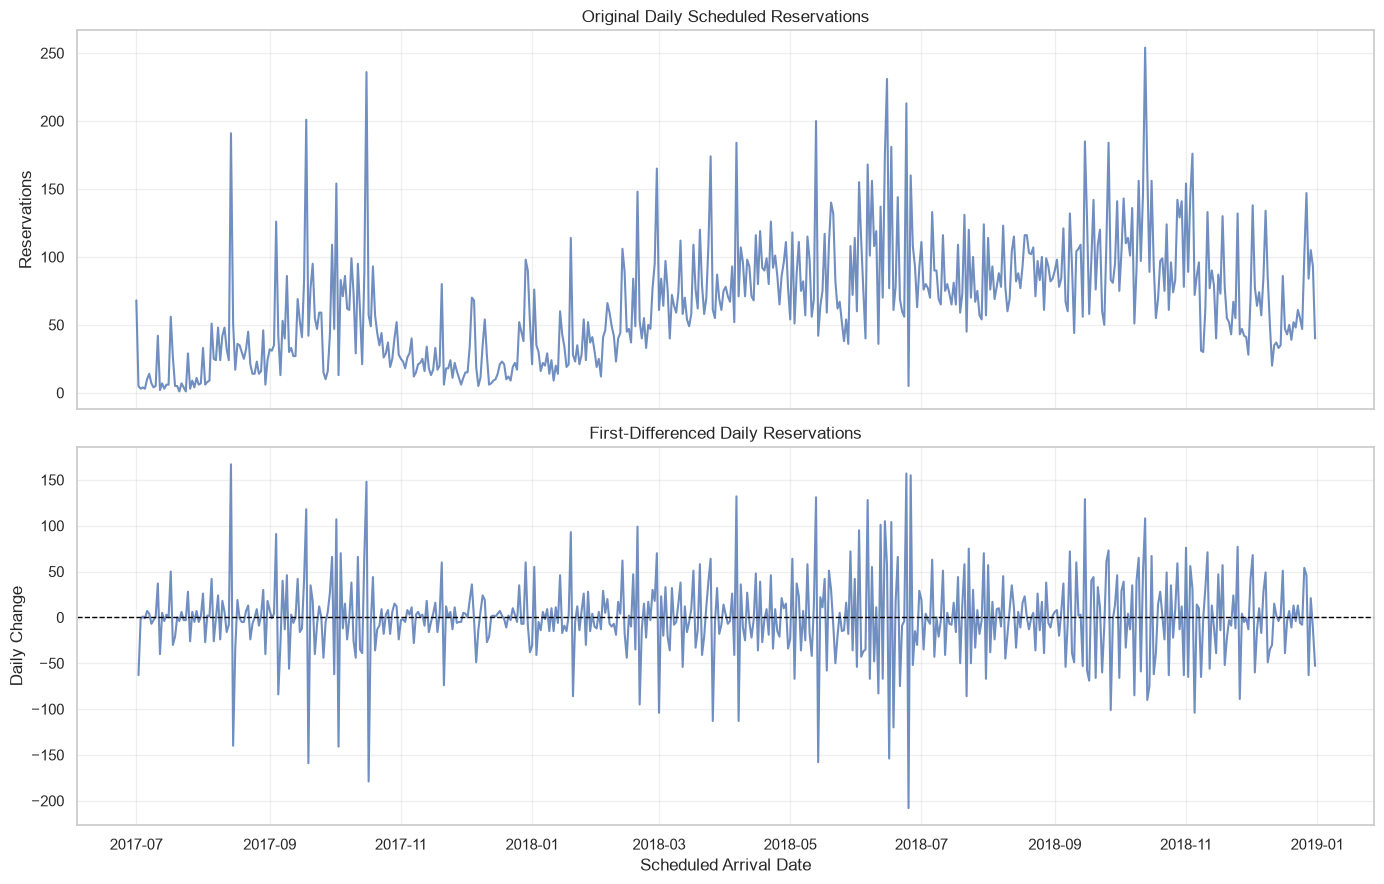

ADF Test Comparison:
Original Series ADF Statistic: -2.3093
Original Series P-Value: 0.168979
Differenced Series ADF Statistic: -11.6737
Differenced Series P-Value: 0.000000

First-Differenced Series Summary:
count    548.00
mean      -0.05
std       44.82
min     -208.00
25%      -19.00
50%       -0.50
75%       18.00
max      167.00


In [35]:
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

daily_reservations = daily_booking_status["Total_Reservations"].copy()

differenced_reservations = daily_reservations.diff().dropna()

adf_original = adfuller(daily_reservations, autolag="AIC")
adf_differenced = adfuller(differenced_reservations, autolag="AIC")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    daily_reservations.index,
    daily_reservations,
    alpha=0.8
)

axes[0].set_title("Original Daily Scheduled Reservations")
axes[0].set_ylabel("Reservations")
axes[0].grid(alpha=0.3)

axes[1].plot(
    differenced_reservations.index,
    differenced_reservations,
    alpha=0.8
)

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("First-Differenced Daily Reservations")
axes[1].set_xlabel("Scheduled Arrival Date")
axes[1].set_ylabel("Daily Change")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ADF Test Comparison:")
print(f"Original Series ADF Statistic: {adf_original[0]:.4f}")
print(f"Original Series P-Value: {adf_original[1]:.6f}")
print(f"Differenced Series ADF Statistic: {adf_differenced[0]:.4f}")
print(f"Differenced Series P-Value: {adf_differenced[1]:.6f}")

print("\nFirst-Differenced Series Summary:")
print(differenced_reservations.describe().round(2).to_string())

#### Key Observations
- **Improved Stationarity:** First-order differencing reduces the ADF statistic from -2.3093 to -11.6737, with the p-value falling below 0.000001, providing strong evidence against a unit root in the differenced series.
- **Daily Reservation Changes:** The differenced series has a mean of -0.05 and a median of -0.50, indicating that positive and negative daily changes approximately balance over the observation period.
- **Substantial Daily Fluctuations:** Daily changes range from -208 to +167 reservations, with a standard deviation of 44.82, demonstrating considerable short-term variability despite the improved ADF result.
- **Forecasting Implications:** First-order differencing is a potential option for ARIMA-family models, although its suitability must be evaluated alongside other diagnostics and out-of-sample forecasting performance.

#### Examining Autocorrelation After Differencing

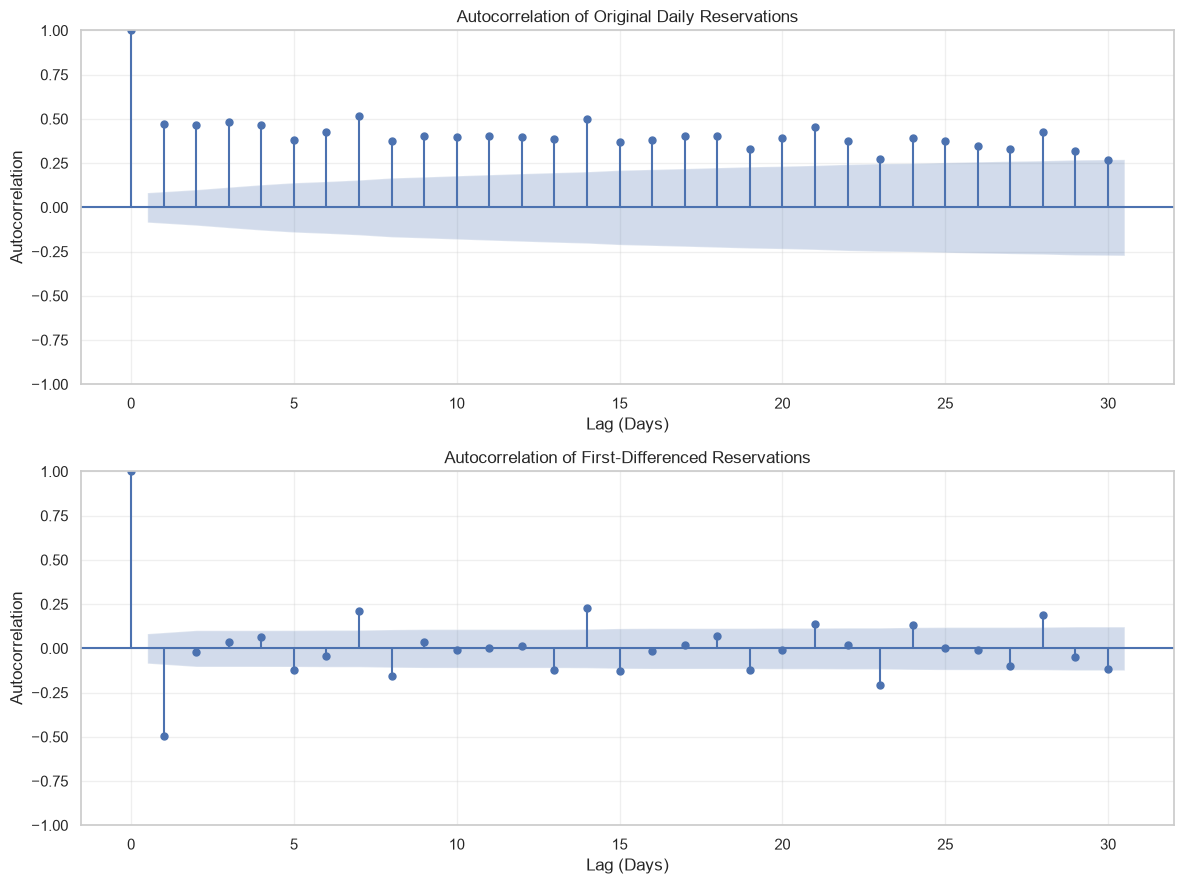

Autocorrelation Comparison:
 Lag_Days  Original_ACF  Differenced_ACF
        1        0.4714          -0.4957
        2        0.4673          -0.0227
        3        0.4879           0.0349
        7        0.5222           0.2154
       14        0.5137           0.2321
       21        0.4745           0.1404
       28        0.4502           0.1904
       30        0.2834          -0.1209


In [36]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

selected_lags = [1, 2, 3, 7, 14, 21, 28, 30]

acf_comparison = pd.DataFrame({
    "Lag_Days": selected_lags,
    "Original_ACF": [
        daily_reservations.autocorr(lag=lag)
        for lag in selected_lags
    ],
    "Differenced_ACF": [
        differenced_reservations.autocorr(lag=lag)
        for lag in selected_lags
    ]
})

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

plot_acf(
    daily_reservations,
    lags=30,
    alpha=0.05,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation of Original Daily Reservations")
axes[0].set_xlabel("Lag (Days)")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(alpha=0.3)

plot_acf(
    differenced_reservations,
    lags=30,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("Autocorrelation of First-Differenced Reservations")
axes[1].set_xlabel("Lag (Days)")
axes[1].set_ylabel("Autocorrelation")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Autocorrelation Comparison:")
print(acf_comparison.round(4).to_string(index=False))

#### Key Observations
- **Reduced Temporal Persistence:** First-order differencing substantially reduces autocorrelation at most selected lags, with lag 2 decreasing from 0.4673 to -0.0227 and lag 3 from 0.4879 to 0.0349.
- **Negative First-Lag Relationship:** The differenced series exhibits a strong negative lag-1 autocorrelation of -0.4957, indicating that daily increases are often followed by decreases, and vice versa.
- **Remaining Weekly Relationships:** Positive autocorrelation persists at lags 7 (0.2154), 14 (0.2321), 21 (0.1404), and 28 (0.1904), suggesting that weekly recurring patterns may remain after removing much of the original persistence.
- **Forecasting Implications:** The remaining weekly correlations support investigating seasonal forecasting methods, while the negative lag-1 relationship warrants careful consideration when selecting differencing and autoregressive components.

#### Examining Weekly Seasonal Differencing

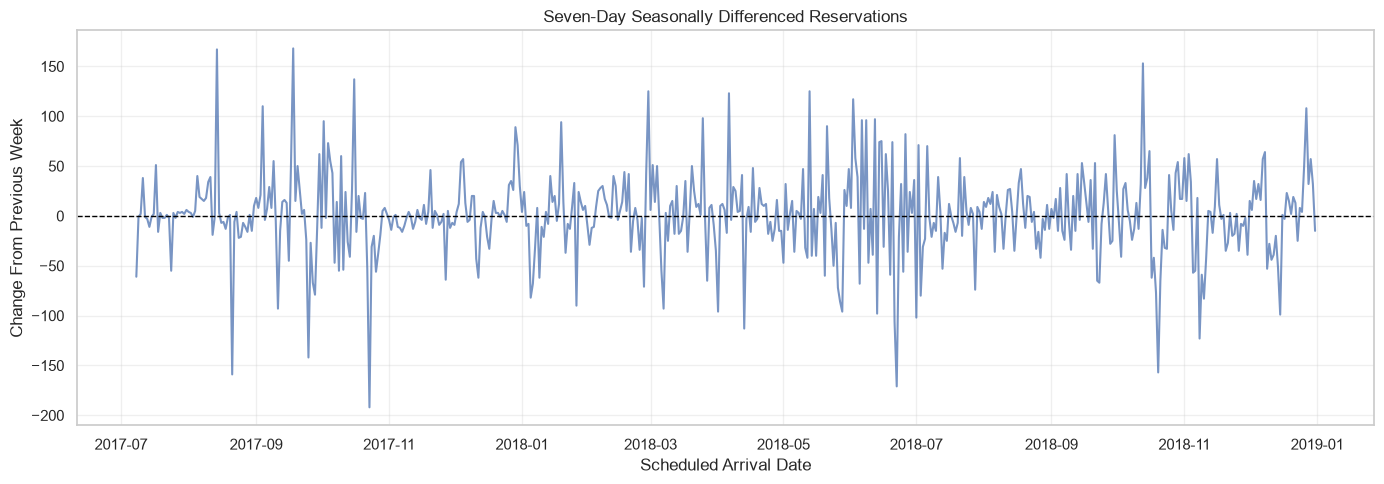

Differencing Method Comparison:
                   Series  Observations  ADF_Statistic  ADF_P_Value  Standard_Deviation  Lag_1_ACF  Lag_7_ACF  Lag_14_ACF
                 Original           549        -2.3093        0.169             43.5620     0.4714     0.5222      0.5137
        First_Differenced           548       -11.6737        0.000             44.8226    -0.4957     0.2154      0.2321
Seasonally_Differenced_7D           542        -6.6872        0.000             42.5183     0.1232    -0.4911      0.0343


In [37]:
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

seasonally_differenced_reservations = daily_reservations.diff(7).dropna()

series_comparison = {
    "Original": daily_reservations,
    "First_Differenced": differenced_reservations,
    "Seasonally_Differenced_7D": seasonally_differenced_reservations
}

comparison_results = []

for name, series in series_comparison.items():
    adf_result = adfuller(series, autolag="AIC")

    comparison_results.append({
        "Series": name,
        "Observations": len(series),
        "ADF_Statistic": adf_result[0],
        "ADF_P_Value": adf_result[1],
        "Standard_Deviation": series.std(),
        "Lag_1_ACF": series.autocorr(lag=1),
        "Lag_7_ACF": series.autocorr(lag=7),
        "Lag_14_ACF": series.autocorr(lag=14)
    })

seasonal_comparison = pd.DataFrame(comparison_results)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    seasonally_differenced_reservations.index,
    seasonally_differenced_reservations,
    alpha=0.75
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Seven-Day Seasonally Differenced Reservations")
ax.set_xlabel("Scheduled Arrival Date")
ax.set_ylabel("Change From Previous Week")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Differencing Method Comparison:")
print(seasonal_comparison.round(4).to_string(index=False))

#### Key Observations
- **Improved Stationarity:** Both first-order and seven-day seasonal differencing produce ADF p-values below 0.001, providing strong evidence against a unit root in the transformed series.
- **Different Autocorrelation Patterns:** First-order differencing produces a negative lag-1 autocorrelation of -0.4957, while seasonal differencing reduces lag-1 autocorrelation to 0.1232 but introduces a negative lag-7 correlation of -0.4911.
- **Forecasting Implications:** Seasonal differencing produces slightly lower variability (42.52) than first-order differencing (44.82). However, neither transformation can be considered superior without evaluating residual behavior and out-of-sample forecasting accuracy.

#### Examining Partial Autocorrelation

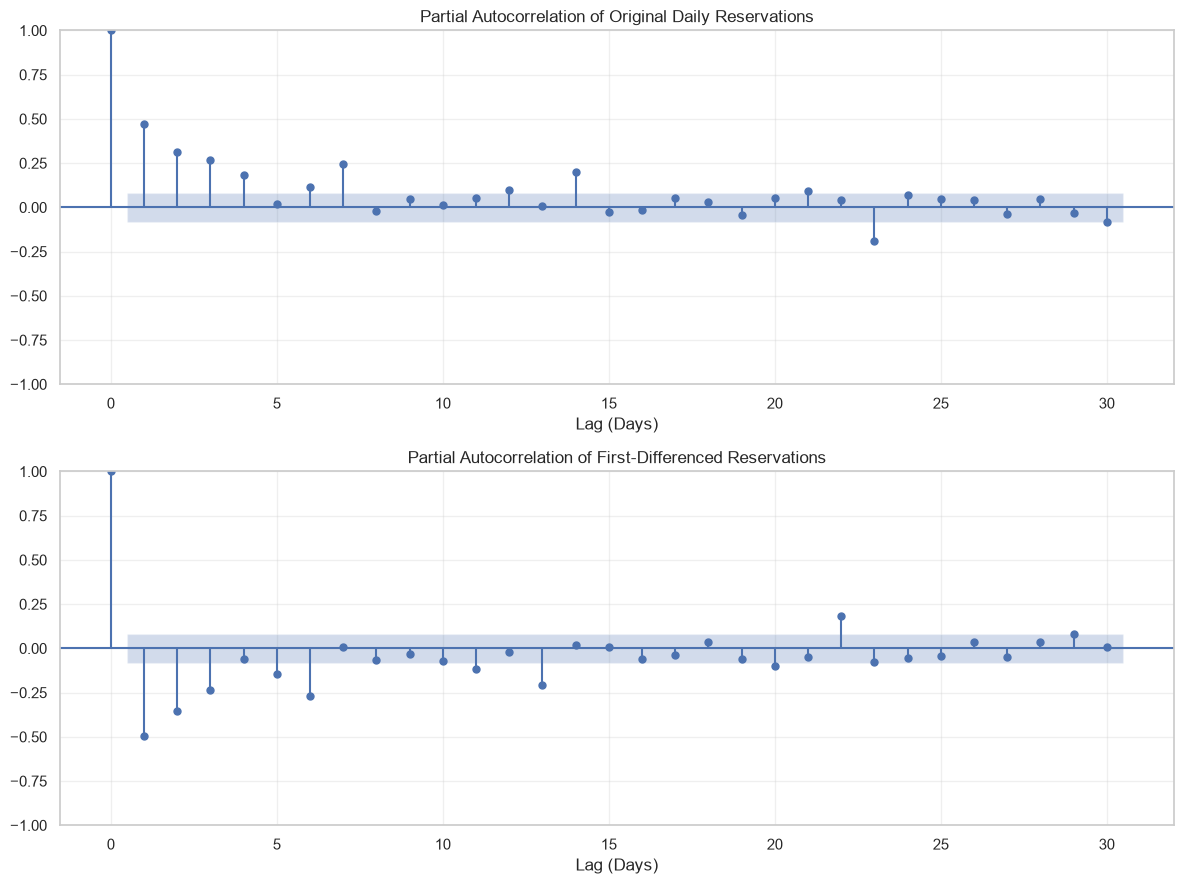

Partial Autocorrelation Comparison:
 Lag_Days  Original_PACF  Differenced_PACF
        1         0.4713           -0.4941
        2         0.3138           -0.3530
        3         0.2662           -0.2340
        7         0.2458            0.0067
       14         0.2000            0.0209
       21         0.0930           -0.0487
       28         0.0494            0.0333
       30        -0.0832            0.0072


In [38]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import pacf
import matplotlib.pyplot as plt

selected_lags = [1, 2, 3, 7, 14, 21, 28, 30]

original_pacf = pacf(
    daily_reservations,
    nlags=30,
    method="ywm"
)

differenced_pacf = pacf(
    differenced_reservations,
    nlags=30,
    method="ywm"
)

pacf_comparison = pd.DataFrame({
    "Lag_Days": selected_lags,
    "Original_PACF": [
        original_pacf[lag] for lag in selected_lags
    ],
    "Differenced_PACF": [
        differenced_pacf[lag] for lag in selected_lags
    ]
})

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

plot_pacf(
    daily_reservations,
    lags=30,
    method="ywm",
    ax=axes[0]
)

axes[0].set_title("Partial Autocorrelation of Original Daily Reservations")
axes[0].set_xlabel("Lag (Days)")
axes[0].grid(alpha=0.3)

plot_pacf(
    differenced_reservations,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("Partial Autocorrelation of First-Differenced Reservations")
axes[1].set_xlabel("Lag (Days)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Partial Autocorrelation Comparison:")
print(pacf_comparison.round(4).to_string(index=False))


#### Key Observations
- **Original Series Dependencies:** The original series exhibits positive partial autocorrelation at lags 1 (0.4713), 2 (0.3138), and 3 (0.2662), indicating meaningful short-term relationships after accounting for intermediate lags.
- **Differenced Series Behavior:** First-order differencing produces negative partial autocorrelation at lags 1 (-0.4941), 2 (-0.3530), and 3 (-0.2340), while the selected longer-lag values are substantially closer to zero.
- **Weekly Relationships:** The original series retains positive PACF values at lags 7 (0.2458) and 14 (0.2000), but these decline to 0.0067 and 0.0209 after differencing. This suggests that the weekly ACF relationships may not represent strong direct dependencies once shorter lags are accounted for.
- **Forecasting Implications:** The results support investigating short-lag autoregressive structures alongside seasonal alternatives, with model selection ultimately determined through chronological validation.

#### Examining Trend and Weekly Seasonal Components

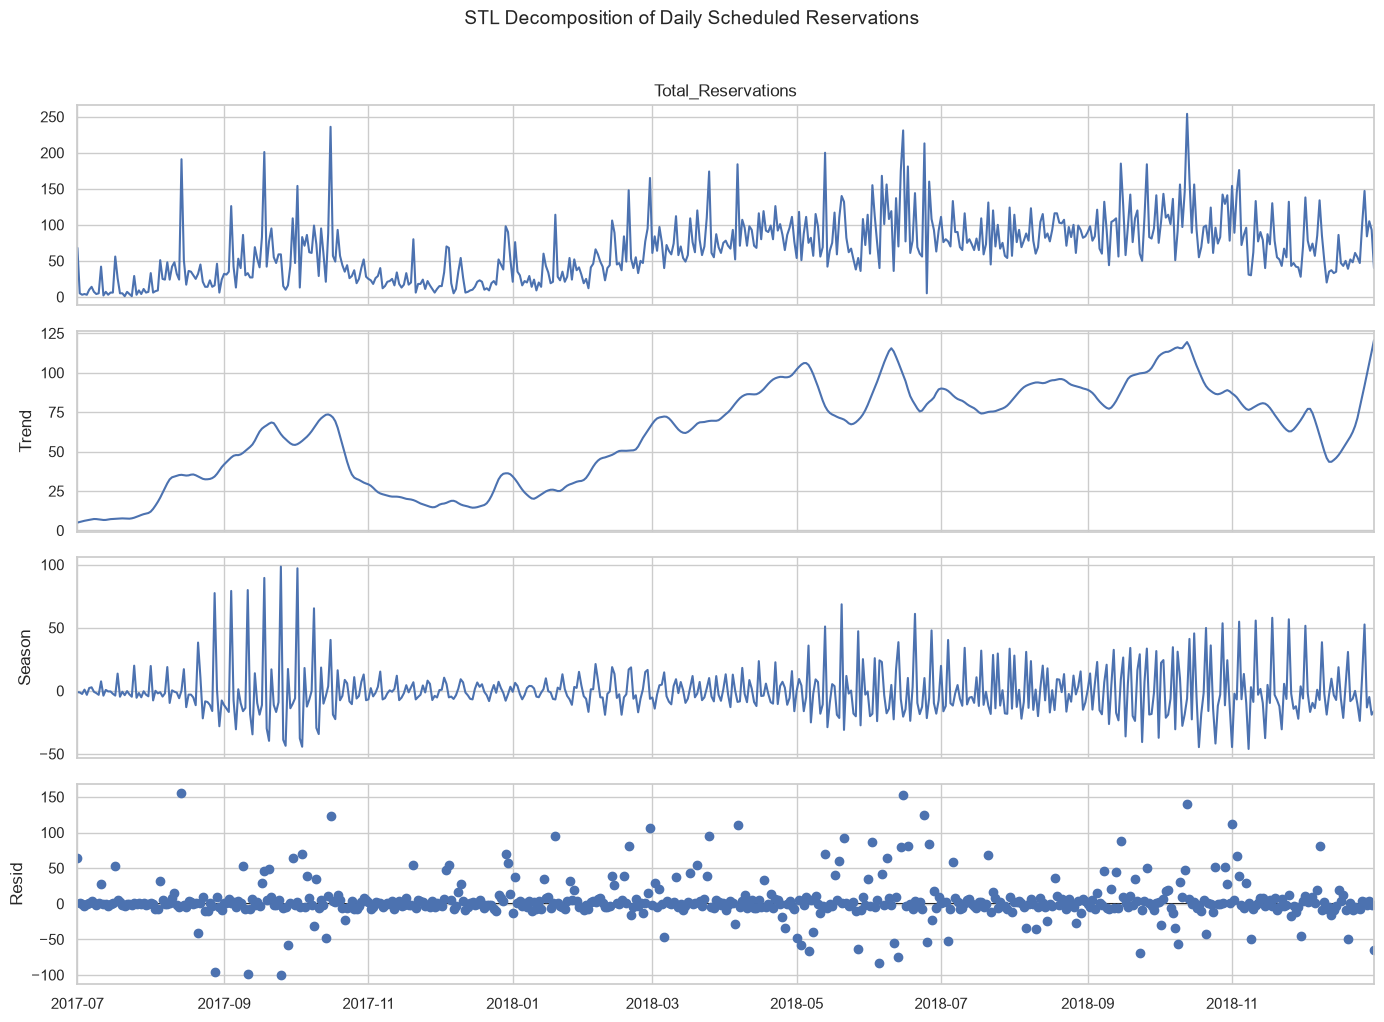

STL Component Summary:
       Observed   Trend  Seasonal  Residual
count    549.00  549.00    549.00    549.00
mean      66.01   61.56     -0.04      4.49
std       43.56   30.48     19.57     28.14
min        1.00    5.01    -46.08   -100.55
25%       32.00   33.51     -9.92     -4.42
50%       61.00   68.47     -2.84      0.59
75%       92.00   86.37      5.55      5.73
max      254.00  120.61     98.48    155.46

Trend Component:
Minimum: 5.01
Maximum: 120.61
Standard Deviation: 30.48

Seasonal Component:
Minimum: -46.08
Maximum: 98.48
Standard Deviation: 19.57

Residual Component:
Mean: 4.49
Standard Deviation: 28.14

Decomposition Strength:
Trend Strength: 0.5382
Weekly Seasonal Strength: 0.1908


In [39]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

stl_result = STL(
    daily_reservations,
    period=7,
    robust=True
).fit()

stl_components = pd.DataFrame({
    "Observed": daily_reservations,
    "Trend": stl_result.trend,
    "Seasonal": stl_result.seasonal,
    "Residual": stl_result.resid
})

fig = stl_result.plot()
fig.set_size_inches(14, 10)
fig.suptitle(
    "STL Decomposition of Daily Scheduled Reservations",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

print("STL Component Summary:")
print(stl_components.describe().round(2).to_string())

print("\nTrend Component:")
print(f"Minimum: {stl_components['Trend'].min():.2f}")
print(f"Maximum: {stl_components['Trend'].max():.2f}")
print(f"Standard Deviation: {stl_components['Trend'].std():.2f}")

print("\nSeasonal Component:")
print(f"Minimum: {stl_components['Seasonal'].min():.2f}")
print(f"Maximum: {stl_components['Seasonal'].max():.2f}")
print(f"Standard Deviation: {stl_components['Seasonal'].std():.2f}")

print("\nResidual Component:")
print(f"Mean: {stl_components['Residual'].mean():.2f}")
print(f"Standard Deviation: {stl_components['Residual'].std():.2f}")

trend_strength = max(
    0,
    1 - stl_components["Residual"].var() /
    (stl_components["Trend"] + stl_components["Residual"]).var()
)

seasonal_strength = max(
    0,
    1 - stl_components["Residual"].var() /
    (stl_components["Seasonal"] + stl_components["Residual"]).var()
)

print("\nDecomposition Strength:")
print(f"Trend Strength: {trend_strength:.4f}")
print(f"Weekly Seasonal Strength: {seasonal_strength:.4f}")

#### Key Observations
- **Trend Dominance:** The STL decomposition estimates a trend strength of 0.5382, with trend values ranging from 5.01 to 120.61 reservations, indicating substantial changes in the underlying reservation level.
- **Limited Weekly Seasonality:** Weekly seasonal strength is relatively low at 0.1908, suggesting that recurring weekly patterns explain only a limited portion of the observed variation after accounting for the trend.
- **Unexplained Variability:** The residual component has a standard deviation of 28.14 and ranges from -100.55 to 155.46, indicating considerable variation not captured by the estimated trend and weekly seasonal components.
- **Forecasting Implications:** Trend-aware methods appear particularly relevant, while weekly seasonal features should be evaluated empirically rather than assumed to provide substantial predictive improvements.

#### Examining Extreme Daily Reservation Volumes

In [40]:
daily_reservations = daily_booking_status["Total_Reservations"].copy()

q1 = daily_reservations.quantile(0.25)
q3 = daily_reservations.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

extreme_days = daily_reservations[
    (daily_reservations < lower_bound) |
    (daily_reservations > upper_bound)
]

print("IQR-Based Extreme Value Analysis:")
print(f"First Quartile (Q1): {q1:.2f}")
print(f"Third Quartile (Q3): {q3:.2f}")
print(f"Interquartile Range: {iqr:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

print(f"\nExtreme Days Identified: {len(extreme_days):,}")
print(f"Percentage of Days: {len(extreme_days) / len(daily_reservations) * 100:.2f}%")

print("\nTop 10 Highest Reservation Days:")
print(daily_reservations.nlargest(10).to_string())

print("\nTop 10 Lowest Reservation Days:")
print(daily_reservations.nsmallest(10).to_string())

print("\nExtreme Days by Year:")
print(
    extreme_days.groupby(extreme_days.index.year)
    .size()
    .to_string()
)

IQR-Based Extreme Value Analysis:
First Quartile (Q1): 32.00
Third Quartile (Q3): 92.00
Interquartile Range: 60.00
Lower Bound: -58.00
Upper Bound: 182.00

Extreme Days Identified: 10
Percentage of Days: 1.82%

Top 10 Highest Reservation Days:
2018-10-13    254
2017-10-16    236
2018-06-15    231
2018-06-24    213
2017-09-18    201
2018-05-13    200
2017-08-14    191
2018-09-15    185
2018-04-06    184
2018-09-26    184

Top 10 Lowest Reservation Days:
2017-07-21    1
2017-07-24    1
2017-07-12    2
2017-07-03    3
2017-07-05    3
2017-07-14    3
2017-07-26    3
2017-07-04    4
2017-07-09    4
2017-07-23    4

Extreme Days by Year:
2017    3
2018    7


#### Key Observations
- **Extreme Reservation Days:** The IQR method identifies 10 unusually high-volume days (1.82% of observations), with daily reservations exceeding the upper threshold of 182.
- **Peak Reservation Activity:** The highest daily volume is 254 reservations on October 13, 2018, followed by 236 on October 16, 2017. Seven extreme days occur in 2018 and three in 2017.
- **Low-Volume Days:** The lowest reservation counts are concentrated in July 2017, with several days recording fewer than five reservations. No observations fall below the IQR lower threshold of -58.
- **Forecasting Implications:** Extreme reservation days should be retained unless data-quality issues are identified, as removing genuine demand fluctuations could distort forecasting evaluation.

#### Examining Extreme Reservation Days Relative to Local Trends

In [41]:
historical_mean_30d = daily_reservations.shift(1).rolling(
    window=30,
    min_periods=30
).mean()

historical_std_30d = daily_reservations.shift(1).rolling(
    window=30,
    min_periods=30
).std()

local_extreme_summary = pd.DataFrame({
    "Daily_Reservations": daily_reservations,
    "Historical_Mean_30D": historical_mean_30d,
    "Historical_Std_30D": historical_std_30d
})

local_extreme_summary["Local_Z_Score"] = (
    local_extreme_summary["Daily_Reservations"]
    - local_extreme_summary["Historical_Mean_30D"]
) / local_extreme_summary["Historical_Std_30D"].replace(0, float("nan"))

global_extreme_comparison = local_extreme_summary.loc[
    extreme_days.index
].copy()

global_extreme_comparison["Above_3_Std"] = (
    global_extreme_comparison["Local_Z_Score"] > 3
)

print("Global Extreme Days Compared With Historical Trends:")
print(global_extreme_comparison.round(2).to_string())

print("\nLocal Extreme Value Summary:")
print(
    f"Global Extreme Days Above 3 Historical Standard Deviations: "
    f"{global_extreme_comparison['Above_3_Std'].sum()}"
)

print(
    f"All Days Above 3 Historical Standard Deviations: "
    f"{(local_extreme_summary['Local_Z_Score'] > 3).sum()}"
)

print(
    f"Days With Available Historical Statistics: "
    f"{local_extreme_summary['Local_Z_Score'].notna().sum()}"
)

Global Extreme Days Compared With Historical Trends:
            Daily_Reservations  Historical_Mean_30D  Historical_Std_30D  Local_Z_Score  Above_3_Std
2017-08-14                 191                18.67               16.94          10.17         True
2017-09-18                 201                37.70               25.52           6.40         True
2017-10-16                 236                66.47               41.28           4.11         True
2018-04-06                 184                76.57               26.28           4.09         True
2018-05-13                 200                87.63               21.10           5.33         True
2018-06-15                 231                94.33               41.43           3.30         True
2018-06-24                 213                98.10               50.91           2.26        False
2018-09-15                 185                90.87               20.50           4.59         True
2018-09-26                 184                9

#### Key Observations
- **Locally Extreme Reservation Days:** Eight of the ten globally identified extreme days exceed three standard deviations above their preceding 30-day historical mean, confirming that most remain unusual even after accounting for changing reservation levels.
- **Most Pronounced Deviation:** August 14, 2017, records the highest local Z-score of 10.17, with 191 reservations against a preceding 30-day average of 18.67.
- **Additional Local Extremes:** Across 519 days with sufficient historical observations, 18 days exceed three historical standard deviations, indicating that some locally unusual reservation spikes are not captured by the global IQR threshold.
- **Forecasting Implications:** Both global and historical comparisons reveal occasional substantial reservation spikes. These observations should be retained for modeling, with their influence assessed through forecasting errors.

#### Defining the Forecasting Objective

The StaySense Analytics project focuses on forecasting daily scheduled reservation volumes using historical hotel reservation records.

**Forecasting Configuration**
- **Target Variable:** Total number of reservations associated with each scheduled arrival date.
- **Temporal Frequency:** Daily.
- **Forecast Horizon:** Seven consecutive days.
- **Historical Coverage:** July 1, 2017, to December 31, 2018.
- **Available Observations:** 549 consecutive daily records.
- **Forecasting Approach:** Historical time series forecasting using chronological validation and leakage-aware feature engineering.

**Methodological Considerations**
- Reservations are aggregated by scheduled arrival date rather than actual booking creation date.
- Final reservation status does not establish whether a booking was known at an earlier forecast origin.
- The dataset does not provide actual guest check-in counts or historical booking snapshots.
- Historical lag features and calendar variables will be prioritized over information unavailable at prediction time.
- Forecasting performance will be compared against appropriate naive and seasonal naive baselines.
- The limited observation period restricts the reliability of annual seasonal analysis.